# Sparse wafer-map metrology — part 1: the core reconstruction
Predict a wafer's full 89-site etch-depth map from a few measured sites, with a 90% range at every site.
This notebook: data checks, the second-instrument cross-check, the bad-reading screen,
PCA shapes, the Bayesian fit with 90% ranges, rival A, leave-one-lot-out testing,
and error vs number of sites (inner and outer sites separately).

**To run:** in Colab, Runtime → Run all. The two data files load from this repository's `data/` folder
(or straight from GitHub when that folder isn't there). Runs in under a minute.

Data: Langer et al., BOSCH plasma-etching dataset, Zenodo 2025, doi:10.5281/zenodo.17122442 (CC BY 4.0).

In [1]:
# Tools: numpy for arrays, pandas for tables, matplotlib/seaborn for plots
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Where the data files are: the repository's data/ folder, or GitHub itself (e.g. in Colab)
DATA_URL = 'https://raw.githubusercontent.com/arifulRPI/sparse-wafer-metrology/main/data/'
def data_path(name):
    for folder in ['data', '../data', '.']:
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return DATA_URL + name

# Where figures go: the repository's figures/ folder if we're inside it, else the current folder
FIG_DIR = next((d for d in ['figures', '../figures'] if os.path.isdir(d)), '.')

full = pd.read_csv(data_path('Si_Oxide_etch_89_points.csv'))  # 89 sites per wafer (Feb 2025, KLA Tencor P-17)
rout = pd.read_csv(data_path('Si_Oxide_etch_9_points.csv'))   # 9 routine sites per wafer (etch day, Veeco Dektak 8)
TARGET = 'stepheight'      # main target (one instrument); silicon etch depth is repeated later

## 1. Data checks

In [2]:
# Check 1: columns, and 89 rows per wafer
print(full.columns.tolist())
print('wafers:', full.experiment_key.nunique(), '| rows per wafer:', full.groupby('experiment_key').size().unique())

# Check 2: wafers per lot
print(full.groupby('lot_number').wafer_number.nunique().to_dict())

# Check 3: lot order = etch order (the date is the first 10 characters of experiment_key)
dates = full.groupby('lot_number').experiment_key.first().str[:10]
print(dates.to_dict(), '| dates increase with lot number:', dates.is_monotonic_increasing)

['experiment_key', 'lot_number', 'wafer_number', 'X', 'Y', 'preox_thickness', 'postox_thickness', 'postox_thickness_nan', 'stepheight', 'oxide_etch', 'si_etch']
wafers: 88 | rows per wafer: [89]
{1: 9, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10, 7: 6, 8: 10, 9: 9, 10: 4}
{1: '2024-07-02', 2: '2024-07-05', 3: '2024-07-09', 4: '2024-07-11', 5: '2024-07-19', 6: '2024-08-01', 7: '2024-08-05', 8: '2024-08-07', 9: '2024-08-21', 10: '2024-08-22'} | dates increase with lot number: True


In [3]:
# Build the wafer x site table: one row per wafer, one column per site
full['site'] = list(zip(full.X // 1000, full.Y // 1000))          # site = (x, y) in mm
sites = sorted(full.site.unique(), key=lambda s: (-s[1], s[0]))    # fixed order: top row first
wafers = full[['experiment_key', 'lot_number', 'wafer_number']].drop_duplicates()
wafers = wafers.sort_values(['lot_number', 'wafer_number']).reset_index(drop=True)
Y = full.pivot(index='experiment_key', columns='site', values=TARGET)
Y = Y.loc[wafers.experiment_key, sites].to_numpy()                 # 88 x 89 array of depths (µm)
lot = wafers.lot_number.to_numpy()
xy = np.array(sites, dtype=float)                                  # site coordinates (mm)
r = np.hypot(xy[:, 0], xy[:, 1])                                   # site radius (mm)
inner = r <= 76.5                                                  # 49 inner sites, 40 outer
print('table shape:', Y.shape, '| inner:', inner.sum(), '| outer:', (~inner).sum())

# Check 4: the routine 9 sites are on the 89-site grid
r9 = rout[['loc_id', 'X', 'Y']].drop_duplicates()
routine = [sites.index((x // 1000, y // 1000)) for x, y in zip(r9.X, r9.Y)]
print('routine-9 grid positions found:', len(routine), '| radii (mm):', sorted(int(round(v)) for v in r[routine]))

# Check 5: what the routine 9 see on the first wafer, vs the full map
print('wafer 1: routine 9 span %.1f-%.1f µm, full map %.1f-%.1f µm'
      % (Y[0, routine].min(), Y[0, routine].max(), Y[0].min(), Y[0].max()))

table shape: (88, 89) | inner: 49 | outer: 40
routine-9 grid positions found: 9 | radii (mm): [0, 54, 54, 54, 54, 76, 76, 76, 76]
wafer 1: routine 9 span 41.1-44.5 µm, full map 40.9-53.2 µm


## 2. Cross-check against the second instrument (the routine 9, read on etch day)
The two campaigns used different profilometers. If both are right, each routine reading should
match the full map at the same site, apart from a constant offset between instruments.
We test two pairings: same (x, y), and the site turned 180° (−x, −y).

In [4]:
rout = rout.dropna(subset=['experiment_key'])                      # drop 9 rows with no wafer label
both = sorted(set(rout.experiment_key) & set(wafers.experiment_key))
print('wafers in both campaigns:', len(both))

def pair_differences(turn):
    """Routine reading minus full-map reading at the paired site, for every reading."""
    sign = -1 if turn else 1
    row = {k: i for i, k in enumerate(wafers.experiment_key)}
    d = []
    for _, m in rout[rout.experiment_key.isin(both)].iterrows():
        j = sites.index((sign * m.X // 1000, sign * m.Y // 1000))  # paired site on the full map
        d.append(m[TARGET] - Y[row[m.experiment_key], j])
    return np.array(d)

for turn in [False, True]:
    d = pair_differences(turn)
    offset = d.mean()                                              # one constant offset
    print('180° turn: %-5s | offset %.2f µm | scatter after removing offset (RMS) %.3f µm'
          % (turn, offset, np.sqrt(np.mean((d - offset) ** 2))))

# Is the offset steady from lot to lot? (mean offset per lot, after the turn)
d = pair_differences(True)
lot_of_reading = rout[rout.experiment_key.isin(both)].lot_number.to_numpy()
print('offset per lot (µm):', {int(l): float(round(d[lot_of_reading == l].mean(), 2)) for l in np.unique(lot_of_reading)})

wafers in both campaigns: 73
180° turn: False | offset -1.06 µm | scatter after removing offset (RMS) 1.528 µm
180° turn: True  | offset -1.06 µm | scatter after removing offset (RMS) 0.047 µm
offset per lot (µm): {1: -1.05, 2: -1.07, 3: -1.08, 4: -1.06, 5: -1.06, 6: -1.06, 7: -1.05, 9: -1.05}


## 2b. EDA: one pair grid of what a fab measures (features) against what it misses (targets)
Features: three routine sites (centre, 54 mm, 76 mm). Targets: two edge sites (95 mm) the
routine plan never sees. Colour = lot, light to dark in etch order.
Every site shares the wafer's overall depth, so raw depths correlate at r ≈ 0.9-1.0 for any pair
and the scatter is just a line. So the panels show each site's depth minus its wafer's mean depth
("shape"), which is what the model uses; the upper panels give both correlations (r).

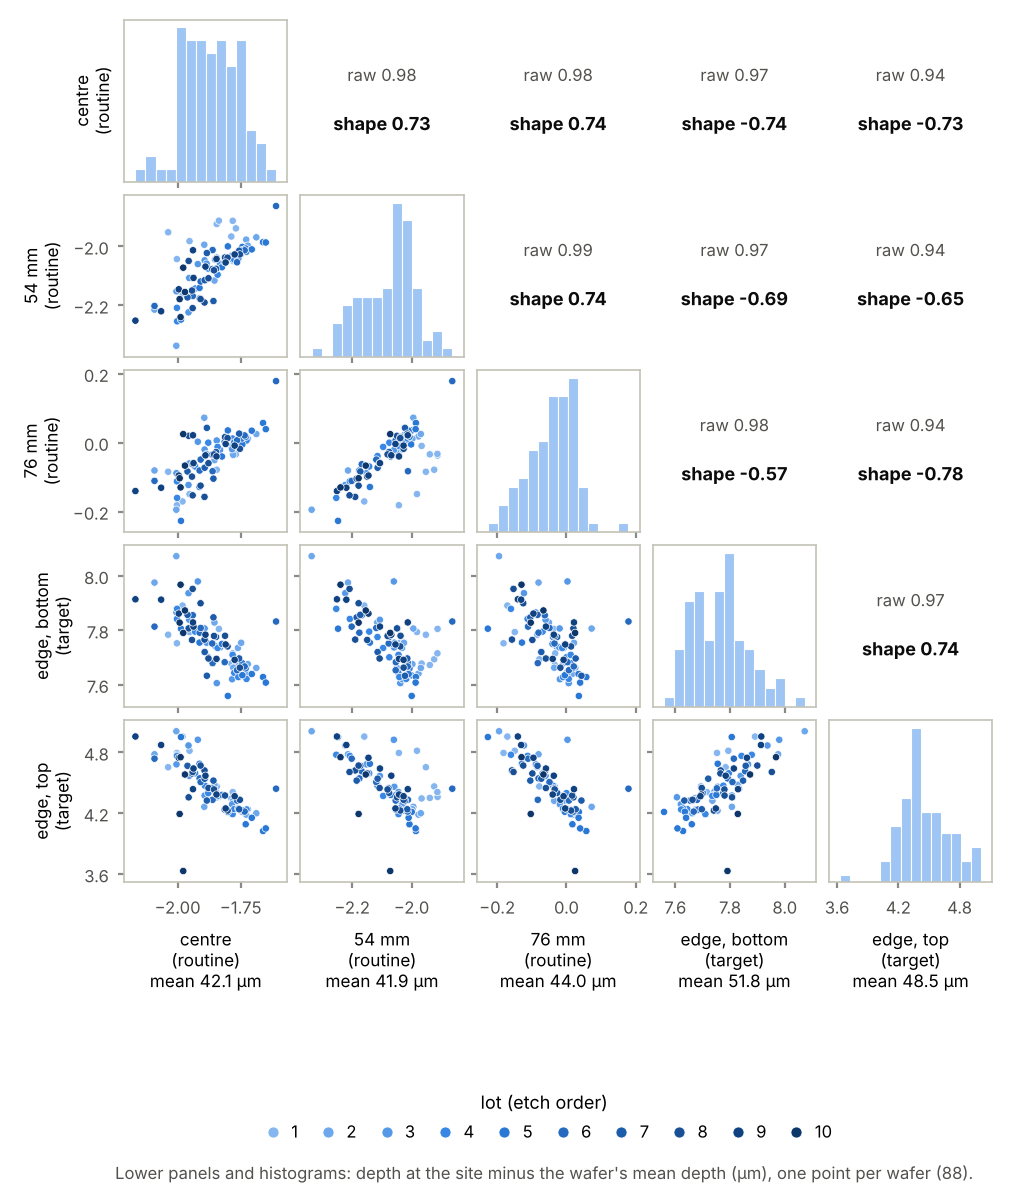

In [5]:
LOT_COLOURS = ['#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6',
               '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']   # one blue, light -> dark
picks = {'centre\n(routine)': (0, 0), '54 mm\n(routine)': (-38, -38), '76 mm\n(routine)': (0, -76),
         'edge, bottom\n(target)': (0, -95), 'edge, top\n(target)': (0, 95)}
names = list(picks)
raw = np.column_stack([Y[:, sites.index(p)] for p in picks.values()])     # raw depths, 88 x 5
shape = raw - Y.mean(axis=1, keepdims=True)                              # minus each wafer's mean depth
colours = [LOT_COLOURS[l - 1] for l in lot]

EDA_SIZE = globals().get('EDA_SIZE', 5.6)   # figure width in inches
n = len(names)
fig, axes = plt.subplots(n, n, figsize=(EDA_SIZE, EDA_SIZE))
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        ax.tick_params(labelsize=6, length=2, color='#8a8984', labelcolor='#52514e')
        for sp in ax.spines.values():
            sp.set_color('#c3c2b7'); sp.set_linewidth(0.6)
        if i > j:                                                         # lower: scatter of shapes
            ax.scatter(shape[:, j], shape[:, i], s=7, c=colours, linewidths=0.25, edgecolors='white')
            ax.xaxis.set_major_locator(plt.MaxNLocator(3, prune='both'))    # few ticks, no crowding
            ax.yaxis.set_major_locator(plt.MaxNLocator(3, prune='both'))
        elif i == j:                                                      # diagonal: spread of one site
            ax.hist(shape[:, i], bins=14, color='#9ec5f4', edgecolor='white', linewidth=0.4)
            ax.set_yticks([])
            ax.xaxis.set_major_locator(plt.MaxNLocator(3, prune='both'))
        else:                                                             # upper: the two correlations
            ax.text(0.5, 0.66, 'raw %.2f' % np.corrcoef(raw[:, i], raw[:, j])[0, 1],
                    ha='center', va='center', transform=ax.transAxes, fontsize=6, color='#52514e')
            ax.text(0.5, 0.36, 'shape %.2f' % np.corrcoef(shape[:, i], shape[:, j])[0, 1],
                    ha='center', va='center', transform=ax.transAxes, fontsize=6.5, color='#0b0b0b', fontweight='bold')
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
        if i < n - 1:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel(names[j] + '\nmean %.1f µm' % raw[:, j].mean(), fontsize=6.2)
        if j > 0 or i == 0:
            if i > j:
                ax.set_yticklabels([])
        else:
            ax.set_ylabel(names[i], fontsize=6.2)
    axes[0, 0].set_ylabel(names[0], fontsize=6.2)
for j in range(n):                                                        # same x range down each column
    lo, hi = shape[:, j].min(), shape[:, j].max()
    pad = 0.08 * (hi - lo)
    for i in range(n):
        if i >= j:
            axes[i, j].set_xlim(lo - pad, hi + pad)
        if i > j:
            lo_i, hi_i = shape[:, i].min(), shape[:, i].max()
            axes[i, j].set_ylim(lo_i - 0.08 * (hi_i - lo_i), hi_i + 0.08 * (hi_i - lo_i))
handles = [plt.Line2D([], [], ls='', marker='o', ms=4, mfc=LOT_COLOURS[k], mec='white', mew=0.3,
                      label=str(k + 1)) for k in range(10)]
fig.legend(handles=handles, title='lot (etch order)', ncol=10, loc='lower center', bbox_to_anchor=(0.5, -0.135),
           fontsize=6, title_fontsize=6.5, frameon=False, handletextpad=0.1, columnspacing=0.8)
fig.text(0.5, -0.155, 'Lower panels and histograms: depth at the site minus the wafer\'s mean depth (µm), one point per wafer (88).',
         ha='center', fontsize=6, color='#52514e')
fig.subplots_adjust(wspace=0.08, hspace=0.08)
fig.savefig(os.path.join(FIG_DIR, 'eda_pairgrid.png'), dpi=250, bbox_inches='tight')
plt.show()

## 3. The bad-reading screen (training wafers only, inside the test loop)
Idea: a glitch is a reading that disagrees with the sites around it.
Depth changes steeply near the edge, so first remove each wafer's level and the typical map;
what is left is the wafer's own deviation, which is smooth. Then compare each reading's
deviation with the median of its (up to 8) touching sites, in robust units (median and MAD).

In [6]:
dist = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])  # site-to-site distances (mm)
nbrs = [np.where((dist[s] > 0) & (dist[s] < 28.5))[0] for s in range(89)]      # touching sites
# Replacement: average of the two closest sites at a similar radius (within 10 mm)
same_ring = [np.argsort(np.where((np.abs(r - r[s]) <= 10) & (dist[s] > 0), dist[s], np.inf))[:2]
             for s in range(89)]

def screen_scores(M, ref):
    """Score every reading in M; 'typical' is learned from the reference maps ref (training wafers)."""
    typical = np.median(ref - np.median(ref, axis=1, keepdims=True), axis=0)   # typical map shape
    def gap(A):
        dev = A - np.median(A, axis=1, keepdims=True) - typical                # each wafer's own deviation
        return np.stack([dev[:, s] - np.median(dev[:, nbrs[s]], axis=1) for s in range(89)], axis=1)
    g, g_ref = gap(M), gap(ref)
    centre = np.median(g_ref, axis=0)                                  # usual gap at each site
    spread = 1.4826 * np.median(np.abs(g_ref - centre), axis=0)        # MAD, scaled to match a std
    return (g - centre) / spread, g - centre                           # score, and size in µm

def screen(M, ref, threshold):
    """Flag and replace readings one at a time, worst first, until none exceed the threshold.
    One at a time, because a bad reading also shifts its neighbours' medians."""
    M = M.copy()
    flagged = []
    done = np.zeros(M.shape, bool)
    while True:
        z, size = screen_scores(M, ref)
        z[done] = 0                                                    # each reading is flagged at most once
        w, s = np.unravel_index(np.argmax(np.abs(z)), z.shape)        # the most unusual reading left
        if abs(z[w, s]) <= threshold:
            return M, flagged
        flagged.append((w, s, M[w, s], z[w, s], size[w, s]))
        M[w, s] = M[w, same_ring[s]].mean()                          # replace with two same-ring sites
        done[w, s] = True

# Look at the score distribution on all 88 wafers before choosing a threshold
z_all, size_all = screen_scores(Y, Y)
order = np.argsort(-np.abs(z_all).ravel())
for t in order[:4]:
    w, s = divmod(t, 89)
    print('lot %d wafer %d site %s: score %.0f, off by %.2f µm'
          % (lot[w], wafers.wafer_number[w], sites[s], z_all[w, s], size_all[w, s]))

THRESHOLD = 30   # sits in the empty gap between the two outliers and everything else (see printout)
Yclean, flagged = screen(Y, Y, THRESHOLD)
for w, s, v, zz, sz in flagged:
    print('flagged: lot %d wafer %d site %s, read %.1f µm (%.1f µm off), replaced by %.1f µm'
          % (lot[w], wafers.wafer_number[w], sites[s], v, sz, Yclean[w, s]))
suspect = [(w, s) for w, s, *_ in flagged]                            # used later for the second score

lot 6 wafer 7 site (-76, -38): score -248, off by -15.88 µm
lot 3 wafer 2 site (95, -19): score -53, off by -11.49 µm
lot 6 wafer 9 site (0, -19): score -20, off by -0.12 µm
lot 6 wafer 9 site (0, -38): score -17, off by -0.14 µm
flagged: lot 6 wafer 7 site (-76, -38), read 28.9 µm (-15.9 µm off), replaced by 43.3 µm
flagged: lot 3 wafer 2 site (95, -19), read 39.7 µm (-11.5 µm off), replaced by 50.8 µm


## 4. PCA shapes, and what the two bad readings do to them
Remove each wafer's level (its mean depth) and the average map; PCA then finds the few
recurring ways wafers differ in shape. Here on all 88 wafers, only to check the Oct 2026 feasibility run;
inside the test loop PCA sees training lots only.

In [7]:
def pca(M):
    """Shapes (rows of Vt) and the fraction of shape variation each one explains."""
    dev = M - M.mean(axis=1, keepdims=True)          # remove each wafer's level
    D = dev - dev.mean(axis=0)                        # remove the average map
    U, S, Vt = np.linalg.svd(D, full_matrices=False)  # PCA via SVD
    return Vt, S**2 / np.sum(S**2)

for name, M in [('bad readings left in', Y), ('after the screen', Yclean)]:
    Vt, frac = pca(M)
    spike = [np.max(Vt[k]**2) > 0.5 for k in range(4)]   # a "shape" that is mostly one site
    print('%-21s first 5 shapes explain %s | cumulative 3/4/5: %.0f%% / %.0f%% / %.0f%% | single-site shapes in top 4: %d'
          % (name, np.round(100 * frac[:5]).astype(int).tolist(), 100 * frac[:3].sum(),
             100 * frac[:4].sum(), 100 * frac[:5].sum(), sum(spike)))
Vt_raw, frac_raw = pca(Y)
print('share of the two single-site shapes, bad readings left in: %.0f%%' % (100 * frac_raw[:2].sum()))

# The same check on silicon etch depth (step height minus the oxide loss), the other target
Ysi = full.pivot(index='experiment_key', columns='site', values='si_etch').loc[wafers.experiment_key, sites].to_numpy()
Ysi_clean, _ = screen(Ysi, Ysi, THRESHOLD)
print('etch depth after the screen: 3 shapes explain %.0f%%' % (100 * pca(Ysi_clean)[1][:3].sum()))

bad readings left in  first 5 shapes explain [49, 27, 16, 4, 2] | cumulative 3/4/5: 92% / 96% / 98% | single-site shapes in top 4: 2
after the screen      first 5 shapes explain [64, 19, 8, 2, 2] | cumulative 3/4/5: 91% / 93% / 95% | single-site shapes in top 4: 0
share of the two single-site shapes, bad readings left in: 77%
etch depth after the screen: 3 shapes explain 85%


## 5. The model: typical map + level + 4 shapes, fitted to a few readings (Bayesian linear regression)
depth at site s = average map(s) + level + b1*shape1(s) + ... + b4*shape4(s) + leftover(s)
The prior says what values of level and b1..b4 are plausible (learned from training wafers),
so even 3 readings give a sensible answer for 5 unknowns. Leftover = what 4 shapes can't describe.

In [8]:
K = 4   # number of shapes, fixed before testing; 3 and 5 are checked in part 3

def learn(M, K):
    """Learn everything the fit needs from training maps M (rows = wafers)."""
    level = M.mean(axis=1)                                  # each wafer's mean depth
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                  # average map (shape only)
    D = dev - avg
    Vt = np.linalg.svd(D, full_matrices=False)[2][:K]       # the K shapes
    b = D @ Vt.T                                            # how much of each shape every wafer has
    leftover = D - b @ Vt                                   # what the shapes miss
    return dict(avg=avg, shapes=Vt,
                prior_mean=np.r_[level.mean(), np.zeros(K)],              # typical level, zero shapes
                prior_var=np.r_[level.var(ddof=1), b.var(axis=0, ddof=1)],
                noise_var=np.mean(leftover**2, axis=0))                   # leftover spread at each site

def fit(m, idx, y_meas):
    """Posterior for (level, b1..bK) from readings y_meas (wafers x k) at sites idx; full maps + 90% ranges."""
    X_all = np.column_stack([np.ones(89), m['shapes'].T])      # 89 x (K+1): level column + shapes
    X = X_all[idx]                                             # rows for the measured sites
    w = 1 / m['noise_var'][idx]                                # trust each reading by its leftover spread
    P0 = 1 / m['prior_var']                                    # prior strength
    cov = np.linalg.inv(np.diag(P0) + X.T @ (w[:, None] * X))  # posterior spread of the coefficients
    rhs = (P0 * m['prior_mean'])[:, None] + X.T @ (w[:, None] * (y_meas - m['avg'][idx]).T)
    coef = cov @ rhs                                           # posterior mean, one column per wafer
    pred = m['avg'][None, :] + (X_all @ coef).T                # predicted full maps
    sd = np.sqrt(np.sum((X_all @ cov) * X_all, axis=1) + m['noise_var'])   # prediction spread per site
    return pred, 1.645 * sd                                    # 90% range = pred ± 1.645 sd

# Rival A is the same fit with no shapes: the typical map, shifted to match the readings.

## 6. Leave-one-lot-out test on random layouts
For each lot: learn everything (screen, average map, shapes, prior) from the other 9 lots,
then for each of its wafers hide all but k sites, predict the hidden ones, and compare with
the truth. Test wafers are never screened. Each wafer is scored twice:
  A: on all hidden sites;   B: leaving out the two suspect readings.

In [9]:
ks = list(range(3, 14))
N_LAYOUTS = 200
rng = np.random.default_rng(0)
layouts = {k: [rng.choice(89, k, replace=False) for _ in range(N_LAYOUTS)] for k in ks}
layouts['routine 9'] = [np.array(routine)]
layouts['all 89 (floor)'] = [np.arange(89)]
lots = np.unique(lot)
valid = np.ones(Y.shape, bool)                       # for score B: False at the two suspect readings
for w, s in suspect:
    valid[w, s] = False

def new_tally():
    return {key: np.zeros((len(lots), 2)) for key in ['sseA', 'nA', 'sseB', 'nB', 'inside', 'nI']}

methods = {'ours': K, 'rival A': 0}
tally = {(meth, lay): new_tally() for meth in methods for lay in layouts}

for li, L in enumerate(lots):
    tr, te = lot != L, lot == L
    assert L not in set(lot[tr])                                    # leakage check: test lot not in training
    Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)                       # screen training wafers only
    models = {meth: learn(Ytr, kk) for meth, kk in methods.items()}
    Yte, Vte = Y[te], valid[te]                                    # test wafers stay untouched
    for meth, m in models.items():
        for lay, sets in layouts.items():
            t = tally[(meth, lay)]
            for idx in sets:
                pred, half = fit(m, idx, Yte[:, idx])
                hidden = np.ones(89, bool)
                if len(idx) < 89:
                    hidden[idx] = False                            # score only sites we did not measure
                err2 = (pred - Yte) ** 2
                okB = Vte[:, idx].all(axis=1)                      # B skips layouts that use a suspect reading
                for g, region in enumerate([inner, ~inner]):
                    h = hidden & region
                    t['sseA'][li, g] += err2[:, h].sum()
                    t['nA'][li, g] += h.sum() * len(Yte)
                    hB = h[None, :] & Vte & okB[:, None]
                    t['sseB'][li, g] += err2[hB].sum()
                    t['nB'][li, g] += hB.sum()
                    inside = np.abs(pred - Yte) <= half            # true depth inside the 90% range?
                    t['inside'][li, g] += inside[hB].sum()
                    t['nI'][li, g] += hB.sum()

def rmse(meth, lay, score='A', region=None, per_lot=False):
    """Root-mean-square error over hidden sites; region 0 = inner, 1 = outer, None = all."""
    t = tally[(meth, lay)]
    sse, n = t['sse' + score], t['n' + score]
    if region is not None:
        sse, n = sse[:, [region]], n[:, [region]]
    if per_lot:
        return np.sqrt(sse.sum(axis=1) / n.sum(axis=1))
    return np.sqrt(sse.sum() / n.sum())

def coverage(meth, lay, region=None):
    """Share of hidden true depths inside the 90% range (should be about 90%)."""
    t = tally[(meth, lay)]
    g = slice(None) if region is None else [region]
    return t['inside'][:, g].sum() / t['nI'][:, g].sum()

## 7. Results: reproducing the Oct 2026 feasibility run, inner/outer error, error vs number of sites

Oct 2026 feasibility run: ours ~0.10 µm at 3 sites, ~0.086 µm at 5 (bad readings excluded)
now, 3 sites: ours 0.114 (B) / 0.416 (A) µm | rival A 0.149 (B) / 0.278 (A) µm
now, 5 sites: ours 0.084 (B) / 0.298 (A) µm | rival A 0.145 (B) / 0.274 (A) µm

sites            ours in ours out     A in    A out   gain in  gain out
3                  0.068    0.153    0.091    0.198       25%       23%
4                  0.055    0.130    0.088    0.198       37%       34%
5                  0.043    0.116    0.084    0.195       49%       41%
6                  0.038    0.106    0.083    0.194       54%       46%
7                  0.035    0.103    0.083    0.192       58%       47%
8                  0.033    0.098    0.081    0.193       59%       49%
9                  0.030    0.095    0.078    0.192       62%       51%
10                 0.030    0.096    0.079    0.193       62%       50%
11                 0.028    0.090    0.078    0.190       64%       52%
12                 0.027    0.

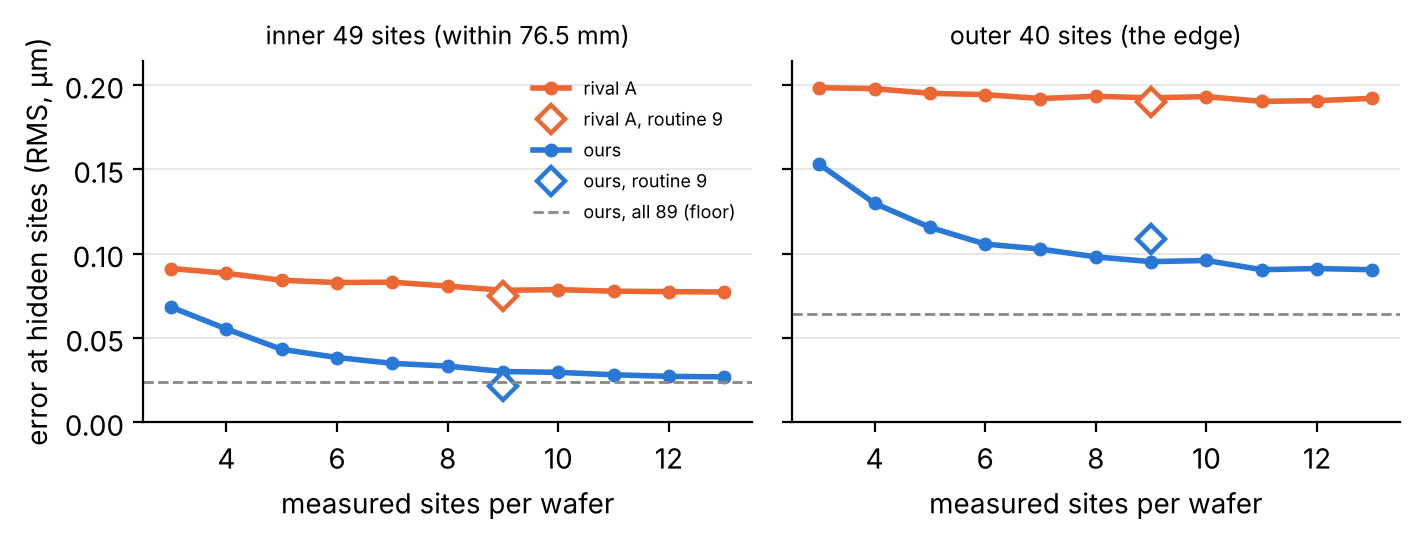

In [10]:
print('Oct 2026 feasibility run: ours ~0.10 µm at 3 sites, ~0.086 µm at 5 (bad readings excluded)')
for k in [3, 5]:
    print('now, %d sites: ours %.3f (B) / %.3f (A) µm | rival A %.3f (B) / %.3f (A) µm'
          % (k, rmse('ours', k, 'B'), rmse('ours', k, 'A'), rmse('rival A', k, 'B'), rmse('rival A', k, 'A')))

print()
print('%-15s %8s %8s %8s %8s %9s %9s' % ('sites', 'ours in', 'ours out', 'A in', 'A out', 'gain in', 'gain out'))
for lay in ks + ['routine 9', 'all 89 (floor)']:
    o = [rmse('ours', lay, 'B', g) for g in (0, 1)]
    a = [rmse('rival A', lay, 'B', g) for g in (0, 1)]
    print('%-15s %8.3f %8.3f %8.3f %8.3f %8.0f%% %8.0f%%' % (lay, o[0], o[1], a[0], a[1],
          100 * (1 - o[0] / a[0]), 100 * (1 - o[1] / a[1])))

print()
for lay in [5, 9, 'routine 9']:
    po, pa = rmse('ours', lay, 'B', per_lot=True), rmse('rival A', lay, 'B', per_lot=True)
    print('%-10s lots where ours beats rival A: %d of 10 | per-lot gain %.0f%% to %.0f%%'
          % (lay, (po < pa).sum(), 100 * (1 - po / pa).min(), 100 * (1 - po / pa).max()))
    print('           per-lot error, ours:', np.round(po, 3).tolist())

print()
for lay in [3, 5, 9, 'routine 9']:
    print('90%% range coverage at %-10s ours %.0f%% (inner %.0f%%, outer %.0f%%), rival A %.0f%%'
          % (lay, 100 * coverage('ours', lay), 100 * coverage('ours', lay, 0), 100 * coverage('ours', lay, 1),
             100 * coverage('rival A', lay)))
print('effect of the two suspect readings at 5 sites (ours): A %.3f vs B %.3f µm' % (rmse('ours', 5, 'A'), rmse('ours', 5, 'B')))

# Figure: error at hidden sites vs number of measured sites, inner and outer separately (score B)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), sharey=True)
for g, ax in enumerate(axes):
    for meth, colour in [('rival A', '#eb6834'), ('ours', '#2a78d6')]:
        e = [rmse(meth, k, 'B', g) for k in ks]
        ax.plot(ks, e, '-o', color=colour, lw=2, ms=4, label=meth)
        ax.plot(9, rmse(meth, 'routine 9', 'B', g), 'D', ms=7, mfc='white', mec=colour, mew=1.6,
                label=meth + ', routine 9')
    ax.axhline(rmse('ours', 'all 89 (floor)', 'B', g), color='#8a8984', ls='--', lw=1, label='ours, all 89 (floor)')
    ax.set_title(['inner 49 sites (within 76.5 mm)', 'outer 40 sites (the edge)'][g], fontsize=9)
    ax.set_xlabel('measured sites per wafer')
    ax.set_ylim(0, None)
    ax.grid(axis='y', color='#e4e3df', lw=0.6)
    ax.spines[['top', 'right']].set_visible(False)
top = max(rmse(m_, k, 'B', 1) for m_ in methods for k in ks)
axes[0].set_ylim(0, 1.08 * top)
axes[0].set_ylabel('error at hidden sites (RMS, µm)')
axes[0].legend(fontsize=6.5, frameon=False, loc='upper right', ncol=1)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'error_vs_sites.png'), dpi=220, bbox_inches='tight')
plt.show()

## 7b. Why lot 1 is the hardest lot
The second PCA shape (on all 88 screened wafers) is a left-right tilt. Compare each lot's amount of it,
then check what the fold that holds out lot 1 has learned.

In [11]:
Vt_all, _ = pca(Yclean)
dev_all = Yclean - Yclean.mean(axis=1, keepdims=True)
amount = (dev_all - dev_all.mean(axis=0)) @ Vt_all[1]                 # tilt amount for every wafer
print('shape 2 vs x position: r = %.2f (a left-right tilt)' % np.corrcoef(Vt_all[1], xy[:, 0])[0, 1])
print('tilt amount, lot 1 wafers:', np.round(amount[lot == 1], 2).tolist())
print('largest tilt amount in any other lot: %.2f' % np.abs(amount[lot != 1]).max())
print('per-lot error with all 89 sites measured (the floor, score B):',
      np.round(rmse('ours', 'all 89 (floor)', 'B', per_lot=True), 3).tolist())

# Does a wider prior help lot 1? (an exploratory check only; any real choice is made on inner splits)
for factor in [1, 4, 16]:
    errs = []
    for L in lots:
        Ytr, _ = screen(Y[lot != L], Y[lot != L], THRESHOLD)
        m = learn(Ytr, K)
        m['prior_var'][1:] *= factor                                 # widen the shape-weight prior
        te = np.where(lot == L)[0]
        sse = n = 0
        for idx in layouts[5]:
            pred, _ = fit(m, idx, Y[te][:, idx])
            ok = valid[te][:, idx].all(axis=1)
            h = np.ones(89, bool); h[idx] = False
            M = h[None, :] & valid[te] & ok[:, None]
            sse += ((pred - Y[te]) ** 2)[M].sum(); n += M.sum()
        errs.append(np.sqrt(sse / n))
    print('prior x%-2d  error at 5 sites per lot:' % factor, np.round(errs, 3).tolist())

shape 2 vs x position: r = -0.94 (a left-right tilt)
tilt amount, lot 1 wafers: [0.25, 1.59, 2.01, 1.83, 1.65, 1.61, 0.83, 1.33, 1.07]
largest tilt amount in any other lot: 0.88
per-lot error with all 89 sites measured (the floor, score B): [0.087, 0.038, 0.025, 0.025, 0.029, 0.038, 0.037, 0.056, 0.035, 0.073]


prior x1   error at 5 sites per lot: [0.167, 0.065, 0.062, 0.044, 0.061, 0.068, 0.063, 0.093, 0.06, 0.1]


prior x4   error at 5 sites per lot: [0.172, 0.072, 0.063, 0.047, 0.066, 0.085, 0.074, 0.108, 0.069, 0.115]


prior x16  error at 5 sites per lot: [0.213, 0.095, 0.073, 0.063, 0.087, 0.122, 0.097, 0.136, 0.09, 0.151]


## 8. Why score A is so much worse: one bad reading used as an input
For the two wafers with a suspect reading, compare layouts that measure it with layouts that don't.

In [12]:
for w, s_bad in suspect:
    L = lot[w]
    Ytr, _ = screen(Y[lot != L], Y[lot != L], THRESHOLD)
    for meth, kk in methods.items():
        m = learn(Ytr, kk)
        measured, hidden_rest, at_bad = [], [], []
        for idx in layouts[5]:
            pred, _ = fit(m, idx, Y[[w]][:, idx])
            err = pred[0] - Y[w]
            others = np.ones(89, bool)
            others[idx] = False
            others[s_bad] = False                     # judge the other hidden sites only
            if s_bad in idx:
                measured.append(np.sqrt(np.mean(err[others] ** 2)))
            else:
                hidden_rest.append(np.sqrt(np.mean(err[others] ** 2)))
                at_bad.append(abs(err[s_bad]))
        print('lot %d wafer %d, %-7s | bad reading measured: other sites off by %.2f µm (RMS, %d layouts)'
              ' | bad reading hidden: other sites %.3f µm, prediction differs from the bad reading by %.1f µm'
              % (L, wafers.wafer_number[w], meth, np.mean(measured), len(measured), np.mean(hidden_rest), np.mean(at_bad)))

lot 6 wafer 7, ours    | bad reading measured: other sites off by 6.84 µm (RMS, 9 layouts) | bad reading hidden: other sites 0.028 µm, prediction differs from the bad reading by 15.9 µm
lot 6 wafer 7, rival A | bad reading measured: other sites off by 2.37 µm (RMS, 9 layouts) | bad reading hidden: other sites 0.099 µm, prediction differs from the bad reading by 16.0 µm
lot 3 wafer 2, ours    | bad reading measured: other sites off by 3.26 µm (RMS, 9 layouts) | bad reading hidden: other sites 0.041 µm, prediction differs from the bad reading by 11.9 µm
lot 3 wafer 2, rival A | bad reading measured: other sites off by 0.42 µm (RMS, 9 layouts) | bad reading hidden: other sites 0.161 µm, prediction differs from the bad reading by 11.6 µm


## 9. Quick test of a proposed revision: check each measured reading against the others
Predict each measured reading from the other k-1, in units of its predicted spread.
A reading far outside (here 6 spreads, a loose first guess) is suspect.

In [13]:
def leave_one_out_scores(m, idx, yk):
    z = np.zeros(yk.shape)
    for j in range(len(idx)):
        rest = np.delete(np.arange(len(idx)), j)
        pred, half = fit(m, idx[rest], yk[:, rest])
        z[:, j] = (yk[:, j] - pred[:, idx[j]]) / (half[idx[j]] / 1.645)
    return np.abs(z)

for k in [5, 9]:
    caught = cases = alarms = clean = 0
    for L in lots:
        te = np.where(lot == L)[0]
        Ytr, _ = screen(Y[lot != L], Y[lot != L], THRESHOLD)
        m = learn(Ytr, K)
        for idx in layouts[k][:100]:
            z = leave_one_out_scores(m, idx, Y[te][:, idx])
            for i, w in enumerate(te):
                bad = [j for j, s in enumerate(idx) if (w, s) in suspect]
                if bad:
                    cases += 1
                    caught += int(np.argmax(z[i]) == bad[0] and z[i].max() > 6)
                else:
                    clean += 1
                    alarms += int(z[i].max() > 6)
    print('%d sites: bad reading caught in %d of %d layouts | clean wafers flagged: %.1f%%'
          % (k, caught, cases, 100 * alarms / clean))

5 sites: bad reading caught in 12 of 12 layouts | clean wafers flagged: 4.1%


9 sites: bad reading caught in 16 of 16 layouts | clean wafers flagged: 3.5%
